In [222]:
# ESTABLISHING FILE PATH

from dotenv import load_dotenv
from pathlib import Path
import os

env_path = Path(
    r"C:\Users\RAHUL DUBEY\OneDrive\Desktop\PORTFOLIO\NEXORA-RETAIL-OPERATIONS-ANALYTICS\.env"
)

load_dotenv(dotenv_path=env_path, override=True)

print("Does the .env file exist?", env_path.is_file())
print("Was DB_USER loaded?", os.getenv("DB_USER") is not None)
print("Was DB_PASSWORD loaded?", os.getenv("DB_PASSWORD") is not None)

Does the .env file exist? True
Was DB_USER loaded? True
Was DB_PASSWORD loaded? True


In [223]:
# ESTABLISHING CONNECTION BETWEEN PYTHON AND SQL DATABASE

from sqlalchemy import create_engine, URL
import os

connection_url = URL.create(
    drivername="mysql+pymysql",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT", "3306")),
    database=os.getenv("DB_NAME")
)

engine = create_engine(connection_url)

print("Database engine created successfully.")

Database engine created successfully.


In [231]:
# EXTRACTING DATA FROM THE SQL DATABASE


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

orders_df = pd.read_sql("select * from orders",engine)
inventory_df = pd.read_sql("select * from inventory",engine)
warehouses_df = pd.read_sql("select * from warehouses",engine)
products_df = pd.read_sql("select * from products",engine)
order_items_df = pd.read_sql("select * from order_items",engine)
orders_df


,order_id,customer_id,warehouse_id,order_date,dispatch_date,delivery_date,promised_delivery_date,order_status,shipping_cost
0,1001,501,1,2025-01-03,2025-01-04,2025-01-06,2025-01-06,Delivered,250.0
1,1002,502,2,2025-01-05,2025-01-07,2025-01-11,2025-01-09,Delayed,320.0
2,1003,503,3,2025-01-07,2025-01-08,2025-01-10,2025-01-11,Delivered,280.0
3,1004,504,1,2025-01-09,2025-01-10,2025-01-12,2025-01-12,Delivered,220.0
4,1005,505,4,2025-01-11,2025-01-14,2025-01-18,2025-01-15,Delayed,350.0
5,1006,506,2,2025-01-14,2025-01-15,2025-01-17,2025-01-18,Delivered,240.0
6,1007,507,3,2025-01-17,2025-01-18,2025-01-23,2025-01-21,Delayed,400.0
7,1008,508,1,2025-01-20,2025-01-21,2025-01-23,2025-01-24,Delivered,260.0
8,1009,509,4,2025-01-22,2025-01-24,2025-01-27,2025-01-26,Delayed,300.0
9,1010,510,2,2025-01-25,2025-01-26,2025-01-29,2025-01-30,Delivered,230.0


In [232]:
# ANALYZING THE DATA

print(orders_df.head(5))
print(inventory_df.tail(3))
print(warehouses_df.shape)
print(products_df.shape)
print(orders_df.shape)
print(order_items_df.shape)
print(inventory_df.shape)

print(orders_df.columns)
orders_df.info()

print("average_shipping_cost",orders_df["shipping_cost"].mean())

print(order_items_df.describe())

   order_id  customer_id  warehouse_id  order_date dispatch_date  \
0      1001          501             1  2025-01-03    2025-01-04   
1      1002          502             2  2025-01-05    2025-01-07   
2      1003          503             3  2025-01-07    2025-01-08   
3      1004          504             1  2025-01-09    2025-01-10   
4      1005          505             4  2025-01-11    2025-01-14   

  delivery_date promised_delivery_date order_status  shipping_cost  
0    2025-01-06             2025-01-06    Delivered          250.0  
1    2025-01-11             2025-01-09      Delayed          320.0  
2    2025-01-10             2025-01-11    Delivered          280.0  
3    2025-01-12             2025-01-12    Delivered          220.0  
4    2025-01-18             2025-01-15      Delayed          350.0  
    inventory_id  warehouse_id  product_id  stock_quantity  reorder_level  \
17            18             4         104               9             12   
18            19       

In [101]:
# DATA CLEANING AND HANDLING NULLS

print(orders_df.isna().sum()) # dispatch date has two null values, delivery data has 3.

print(inventory_df.isna().sum())  # no null values in this table

print(orders_df.loc[orders_df["delivery_date"].isna()])
print(orders_df.loc[orders_df["dispatch_date"].isna(),["order_id","customer_id","order_status"]])

order_id                  0
customer_id               0
warehouse_id              0
order_date                0
dispatch_date             2
delivery_date             3
promised_delivery_date    0
order_status              0
shipping_cost             0
dtype: int64
inventory_id           0
warehouse_id           0
product_id             0
stock_quantity         0
reorder_level          0
last_restocked_date    0
dtype: int64
    order_id  customer_id  warehouse_id  order_date dispatch_date  \
18      1019          519             1  2025-02-21    2025-02-22   
19      1020          520             2  2025-02-24          None   
23      1024          524             2  2025-03-08          None   

   delivery_date promised_delivery_date order_status  shipping_cost  
18          None             2025-02-25   In Transit          310.0  
19          None             2025-02-28   In Transit          200.0  
23          None             2025-03-12    Cancelled            0.0  
    order_id  c

In [102]:
# INVESTIGATING MISSING DELIVERY DATES 

print(orders_df.loc[(orders_df["delivery_date"].isna())&(orders_df["order_status"] == "Delivered")])


print(orders_df.loc[(orders_df["dispatch_date"].isna())&(orders_df["order_status"] == "Delivered")])

Empty DataFrame
Columns: [order_id, customer_id, warehouse_id, order_date, dispatch_date, delivery_date, promised_delivery_date, order_status, shipping_cost]
Index: []
Empty DataFrame
Columns: [order_id, customer_id, warehouse_id, order_date, dispatch_date, delivery_date, promised_delivery_date, order_status, shipping_cost]
Index: []


In [103]:
# VALIDATING DATE COLUMNS 
print(orders_df.dtypes)

# Data Type of order_date is OBJECT
# Data Type of dispatch date is OBJECT
# Data Type of delivery date is OBJECT
# If we eventually want to calculate delivery days from them and perform time series functions, we need to convert them to Datetime 

date_columns = [
    "order_date",
    "dispatch_date",
    "delivery_date",
    "promised_delivery_date"
]
orders_df[date_columns] = orders_df[date_columns].apply(pd.to_datetime)
print(orders_df.dtypes)


order_id                    int64
customer_id                 int64
warehouse_id                int64
order_date                 object
dispatch_date              object
delivery_date              object
promised_delivery_date     object
order_status                  str
shipping_cost             float64
dtype: object
order_id                          int64
customer_id                       int64
warehouse_id                      int64
order_date                datetime64[s]
dispatch_date             datetime64[s]
delivery_date             datetime64[s]
promised_delivery_date    datetime64[s]
order_status                        str
shipping_cost                   float64
dtype: object


In [104]:

# Calculating ORDER FULFILLMENT DAYS and DELIVERY DAYS

orders_df["fulfillment_days"] = (orders_df["delivery_date"] - orders_df["order_date"]).dt.days

orders_df["delivery_days"] = (orders_df["delivery_date"] - orders_df["dispatch_date"]).dt.days

orders_df["dispatch_days"] = (orders_df["dispatch_date"] - orders_df["order_date"]).dt.days
orders_df


,order_id,customer_id,warehouse_id,order_date,dispatch_date,delivery_date,promised_delivery_date,order_status,shipping_cost,fulfillment_days,delivery_days,dispatch_days
0,1001,501,1,2025-01-03,2025-01-04,2025-01-06,2025-01-06,Delivered,250.0,3.0,2.0,1.0
1,1002,502,2,2025-01-05,2025-01-07,2025-01-11,2025-01-09,Delayed,320.0,6.0,4.0,2.0
2,1003,503,3,2025-01-07,2025-01-08,2025-01-10,2025-01-11,Delivered,280.0,3.0,2.0,1.0
3,1004,504,1,2025-01-09,2025-01-10,2025-01-12,2025-01-12,Delivered,220.0,3.0,2.0,1.0
4,1005,505,4,2025-01-11,2025-01-14,2025-01-18,2025-01-15,Delayed,350.0,7.0,4.0,3.0
5,1006,506,2,2025-01-14,2025-01-15,2025-01-17,2025-01-18,Delivered,240.0,3.0,2.0,1.0
6,1007,507,3,2025-01-17,2025-01-18,2025-01-23,2025-01-21,Delayed,400.0,6.0,5.0,1.0
7,1008,508,1,2025-01-20,2025-01-21,2025-01-23,2025-01-24,Delivered,260.0,3.0,2.0,1.0
8,1009,509,4,2025-01-22,2025-01-24,2025-01-27,2025-01-26,Delayed,300.0,5.0,3.0,2.0
9,1010,510,2,2025-01-25,2025-01-26,2025-01-29,2025-01-30,Delivered,230.0,4.0,3.0,1.0


In [105]:
# ORDERS DELIVERED AFTER THE PROMISED DELIVERY DATE

delayed_orders = orders_df.loc[
    orders_df["delivery_date"] > orders_df["promised_delivery_date"],
    ["order_id","warehouse_id","delivery_date","promised_delivery_date","order_status"]
    ]
print(delayed_orders)

    order_id  warehouse_id delivery_date promised_delivery_date order_status
1       1002             2    2025-01-11             2025-01-09      Delayed
4       1005             4    2025-01-18             2025-01-15      Delayed
6       1007             3    2025-01-23             2025-01-21      Delayed
8       1009             4    2025-01-27             2025-01-26      Delayed
11      1012             2    2025-02-12             2025-02-09      Delayed
13      1014             4    2025-02-14             2025-02-12      Delayed
16      1017             3    2025-02-22             2025-02-20      Delayed
21      1022             4    2025-03-12             2025-03-09      Delayed
24      1025             3    2025-03-17             2025-03-15      Delayed
27      1028             2    2025-03-26             2025-03-24      Delayed
29      1030             4    2025-03-30             2025-03-29      Delayed


In [106]:
# ON TIME DELIVERY RATE 

completed_orders = orders_df.loc[orders_df["order_status"].isin(["Delayed","Delivered"])]

valid_completed_orders = completed_orders.loc[(completed_orders["delivery_date"].notna())&(completed_orders["promised_delivery_date"].notna())]

on_time_orders = valid_completed_orders.loc[valid_completed_orders["delivery_date"] <= valid_completed_orders["promised_delivery_date"]]


ON_TIME_DELIVERY_RATE = (len(on_time_orders)/len(valid_completed_orders)) * 100
print("ON_TIME_DELIVERY_RATE",ON_TIME_DELIVERY_RATE)


ON_TIME_DELIVERY_RATE 59.25925925925925


In [107]:
# AVERAGE DELIVERY TRANSIT TIME

average_delivery_transit_time = round(valid_completed_orders["delivery_days"].mean(),0)
print(average_delivery_transit_time)

3.0


In [108]:
# ON TIME DELIVERY RATE FOR EACH WAREHOUSE


# 1st approach
warehouse_performance = valid_completed_orders.groupby("warehouse_id").agg(
    total_completed_orders = ("order_id","count"),
    on_time_orders = ("order_status",(lambda x:(x == "Delivered").sum())
))


# 2nd approach
valid_completed_orders["is_on_time"] = valid_completed_orders["delivery_date"] <= valid_completed_orders["promised_delivery_date"]

warehouse_performance_1 = valid_completed_orders.groupby("warehouse_id").agg(
    total_completed_orders = ("order_id","count"),
    on_time_orders = ("is_on_time","sum")
)


warehouse_performance_1["on_time_delivery_rate"] = round((warehouse_performance_1["on_time_orders"]/warehouse_performance_1["total_completed_orders"])* 100,2)
warehouse_performance_1


final_data = warehouse_performance_1.merge(
    warehouses_df,
    how = "left",
    on = "warehouse_id"
)[["warehouse_id","warehouse_name","city","on_time_delivery_rate"]].sort_values("on_time_delivery_rate",ascending = False)
final_data



,warehouse_id,warehouse_name,city,on_time_delivery_rate
0,1,North Hub,Delhi,100.00
2,3,West Hub,Mumbai,57.14
1,2,South Hub,Bengaluru,50.00
3,4,East Hub,Kolkata,28.57


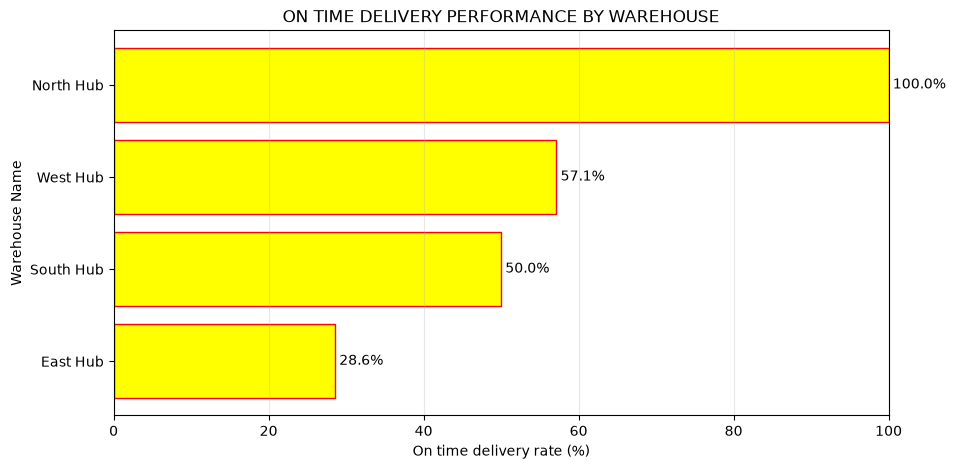

In [110]:
# VISUAL CARD 1 - ON TIME DELIVERY RATE FOR EACH WAREHOUSE

import numpy as np
import matplotlib.pyplot as plt

fig,ax = plt.subplots(figsize = (10,5))
bar = ax.barh(final_data["warehouse_name"],final_data["on_time_delivery_rate"],
        color = "yellow",
              edgecolor = "red"
             )
ax.bar_label(bar,padding = 3,fmt = "%.1f%%")
ax.set_title("ON TIME DELIVERY PERFORMANCE BY WAREHOUSE")
ax.set_xlabel("On time delivery rate (%)")
ax.set_ylabel("Warehouse Name")
ax.set_xlim(0,100)
ax.invert_yaxis()
ax.grid(axis = "x",alpha = 0.3)
plt.show()

                      

In [128]:
# AVERAGE DELIVERY TRANSIT TIME FOR EACH WAREHOUSE (KPI 2)

avg_transit = valid_completed_orders.groupby("warehouse_id",as_index = False).agg(
    avg_transit_time = ("delivery_days","mean")).round(2)


kpi_2 = avg_transit.merge(
    warehouses_df,
    how = "inner",
    on = "warehouse_id"
)[["warehouse_id","warehouse_name","city","region","avg_transit_time"]].sort_values("avg_transit_time",ascending = False)
print(kpi_2)

   warehouse_id warehouse_name       city region  avg_transit_time
3             4       East Hub    Kolkata   East              3.43
2             3       West Hub     Mumbai   West              3.43
1             2      South Hub  Bengaluru  South              3.33
0             1      North Hub      Delhi  North              2.00


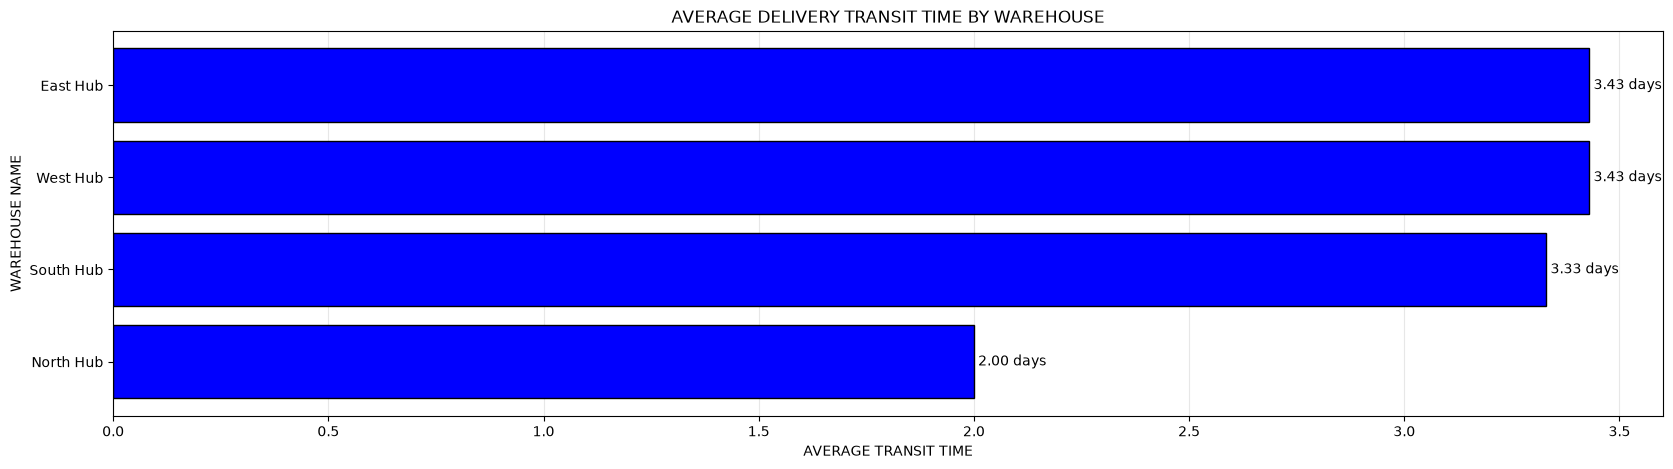

In [140]:
# VISUAL 2 - AVERAGE DELIVERY TRANSIT TIME BY WAREHOUSE

import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize = (20,5))
bar = ax.barh(kpi_2["warehouse_name"],kpi_2["avg_transit_time"],
              color = "blue",
              edgecolor = "black"
             )
ax.bar_label(bar,padding = 3,fmt = "%.2f days")
ax.invert_yaxis()
ax.set_title("AVERAGE DELIVERY TRANSIT TIME BY WAREHOUSE")
ax.set_xlabel("AVERAGE TRANSIT TIME")
ax.set_ylabel("WAREHOUSE NAME")
ax.grid(axis = "x",alpha = 0.3)
ax.set_axisbelow(True)
plt.show()



In [145]:
# BUSINESS ANALYSIS AND INSIGHTS

# A longer transit time does not automatically mean that the orders are being delayed. 
# For eg. if the promised delivery time is 5 days and transit time is 4, its still on time . 

warehouse_performance_2 = warehouse_performance_1.merge(
    avg_transit,
    how = "inner",
    on = "warehouse_id"
)[["warehouse_id","on_time_delivery_rate","avg_transit_time","total_completed_orders"]].sort_values("on_time_delivery_rate",ascending = False)
warehouse_performance_2




,warehouse_id,on_time_delivery_rate,avg_transit_time,total_completed_orders
0,1,100.00,2.00,7
2,3,57.14,3.43,7
1,2,50.00,3.33,6
3,4,28.57,3.43,7


In [151]:
# PRODUCT AND INVENTORY ANALYTICS

# 1. TOP 5 PRODUCTS BY REVENUE


order_items_df["item_revenue"] = order_items_df["quantity"] * order_items_df["unit_selling_price"]
order_items_df

product_revenue = order_items_df.groupby("product_id",as_index = False).agg(
    total_units_sold = ("quantity","sum"),
    total_revenue = ("item_revenue","sum")
)


product_performance = products_df.merge(
    product_revenue,
    how = "inner",
    on = "product_id"
)[["product_id","product_name","category","unit_cost","total_units_sold","total_revenue"]].sort_values("total_revenue",ascending = False)
product_performance

,product_id,product_name,category,unit_cost,total_units_sold,total_revenue
0,101,Laptop,Electronics,35000.0,5,225000.0
1,102,Monitor,Electronics,9000.0,6,72000.0
5,106,Office Desk,Furniture,7000.0,5,47500.0
9,110,Printer,Electronics,8000.0,4,42000.0
4,105,Office Chair,Furniture,4500.0,4,26000.0
6,107,Headphones,Electronics,1800.0,8,22400.0
2,103,Keyboard,Accessories,1400.0,9,18000.0
7,108,Webcam,Electronics,2200.0,5,16000.0
3,104,Mouse,Accessories,300.0,14,7000.0
8,109,Notebook Pack,Stationery,150.0,15,3750.0


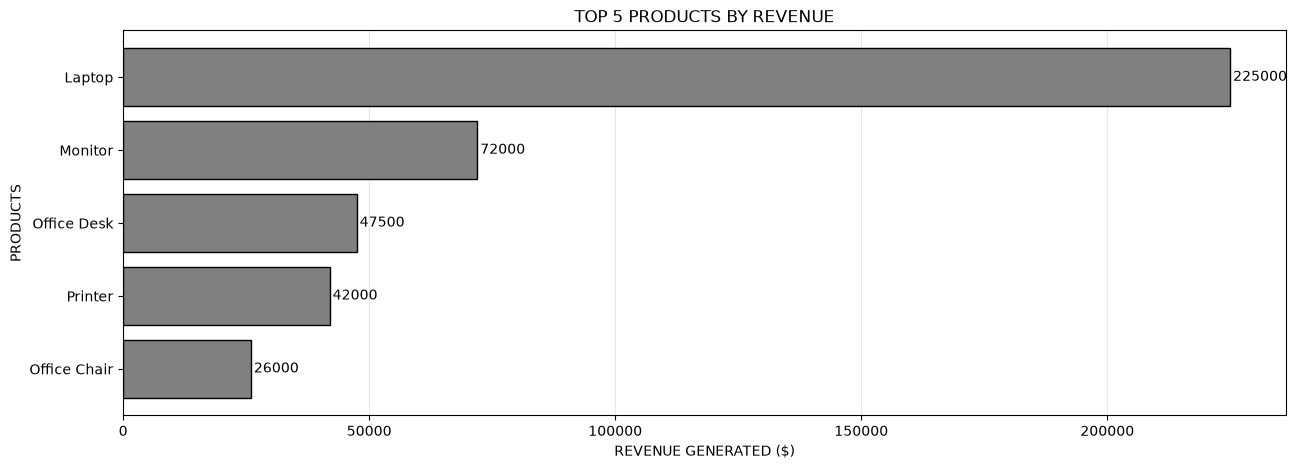

In [161]:
# VISUAL 3 - TOP 5 PRODUCTS BY REVENUE
top_5_products = product_performance.head(5)
import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize = (15,5))
bar = ax.barh(top_5_products["product_name"],top_5_products["total_revenue"],
              color = "grey",
              edgecolor = "black"
             )
ax.invert_yaxis()
ax.bar_label(bar,padding = 2)
ax.set_title("TOP 5 PRODUCTS BY REVENUE")
ax.set_xlabel("REVENUE GENERATED ($)")
ax.set_ylabel("PRODUCTS")
ax.grid(axis = "x",alpha = 0.3)
ax.set_axisbelow(True)
plt.show()


In [167]:
# PRODUCT REVENUE CONTRIBUTION

product_performance
product_performance["revenue_contribution"] = round((product_performance["total_revenue"]/(product_performance["total_revenue"].sum())) * 100,2)

product_performance["cumulative_revenue_pct"] = product_performance["revenue_contribution"].cumsum()
product_performance

,product_id,product_name,category,unit_cost,total_units_sold,total_revenue,revenue_contribution,cumulative_revenue_pct
0,101,Laptop,Electronics,35000.0,5,225000.0,46.91,46.91
1,102,Monitor,Electronics,9000.0,6,72000.0,15.01,61.92
5,106,Office Desk,Furniture,7000.0,5,47500.0,9.90,71.82
9,110,Printer,Electronics,8000.0,4,42000.0,8.76,80.58
4,105,Office Chair,Furniture,4500.0,4,26000.0,5.42,86.00
6,107,Headphones,Electronics,1800.0,8,22400.0,4.67,90.67
2,103,Keyboard,Accessories,1400.0,9,18000.0,3.75,94.42
7,108,Webcam,Electronics,2200.0,5,16000.0,3.34,97.76
3,104,Mouse,Accessories,300.0,14,7000.0,1.46,99.22
8,109,Notebook Pack,Stationery,150.0,15,3750.0,0.78,100.00


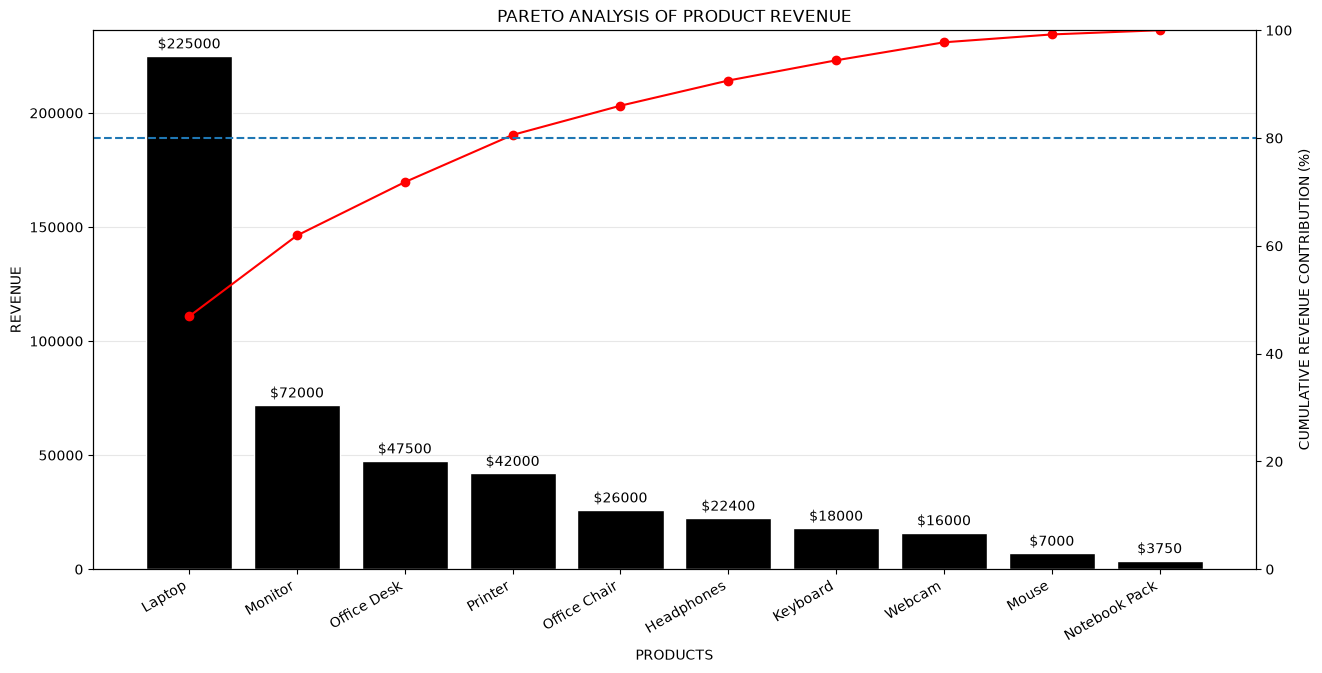

In [181]:
# VISUAL 4 - PARETO CHART FOR REVENUE CONCENTRATION

pareto_data = product_performance.sort_values(
    "total_revenue",
    ascending = False
)
import matplotlib.pyplot as plt
fig,ax1 = plt.subplots(figsize=(15,7))
bar = ax1.bar(pareto_data["product_name"],
               pareto_data["total_revenue"],
               color = "black",
               edgecolor = "white"
              )
ax1.bar_label(bar,padding = 3,fmt = "$%.0f")
ax1.set_title("PARETO ANALYSIS OF PRODUCT REVENUE")
ax1.set_xlabel("PRODUCTS")
ax1.set_ylabel("REVENUE")


ax2 = ax1.twinx()
ax2.plot(pareto_data["product_name"],
         pareto_data["cumulative_revenue_pct"],
         marker = "o",
         color = "red"
        )
ax2.set_ylim(0,100)
ax2.set_ylabel("CUMULATIVE REVENUE CONTRIBUTION (%)")
ax2.axhline(
    y = 80,
    linestyle = "--",
    label = "80% reference"
)
               
plt.setp(
    ax1.get_xticklabels(),
    rotation = 30,
    ha = "right"
)
ax1.grid(axis = "y",alpha = 0.3)
ax1.set_axisbelow(True)

bar_handles,bar_labels = ax1.get_legend_handles_labels()
line_handles,line_labels = ax1.get_legend_handles_labels()
plt.show()



In [186]:
# INVENTORY ANALYSIS 
# classifying each product based on its current stock status.

inventory_analysis = inventory_df.copy()

conditions = [
    inventory_analysis["stock_quantity"] == 0,
    inventory_analysis["stock_quantity"] <= inventory_analysis["reorder_level"]
]

choices = [
    "OUT OF STOCK",
    "REORDER REQUIRED"
]

inventory_analysis["stock_status"] = np.select(
    conditions,
    choices,
    default = "ADEQUATE STOCK"
)
inventory_analysis
    


,inventory_id,warehouse_id,product_id,stock_quantity,reorder_level,last_restocked_date,stock_status
0,1,1,101,8,10,2025-03-01,REORDER REQUIRED
1,2,1,102,25,10,2025-03-05,ADEQUATE STOCK
2,3,1,103,18,15,2025-03-08,ADEQUATE STOCK
3,4,1,104,6,12,2025-03-10,REORDER REQUIRED
4,5,1,105,14,8,2025-03-12,ADEQUATE STOCK
5,6,2,101,5,10,2025-03-02,REORDER REQUIRED
6,7,2,102,12,10,2025-03-06,ADEQUATE STOCK
7,8,2,106,7,8,2025-03-09,REORDER REQUIRED
8,9,2,107,20,10,2025-03-11,ADEQUATE STOCK
9,10,2,108,4,8,2025-03-13,REORDER REQUIRED


In [193]:
# WAREHOUSE INVENTORY ANALYSIS

warehouse_stock_summary = inventory_analysis.groupby(["warehouse_id","stock_status"]).size().unstack(fill_value = 0)
warehouse_stock_summary["total_products"] = warehouse_stock_summary.sum(axis = 1)
print(warehouse_stock_summary)

stock_status  ADEQUATE STOCK  REORDER REQUIRED  total_products
warehouse_id                                                  
1                          3                 2               5
2                          2                 3               5
3                          2                 3               5
4                          2                 3               5


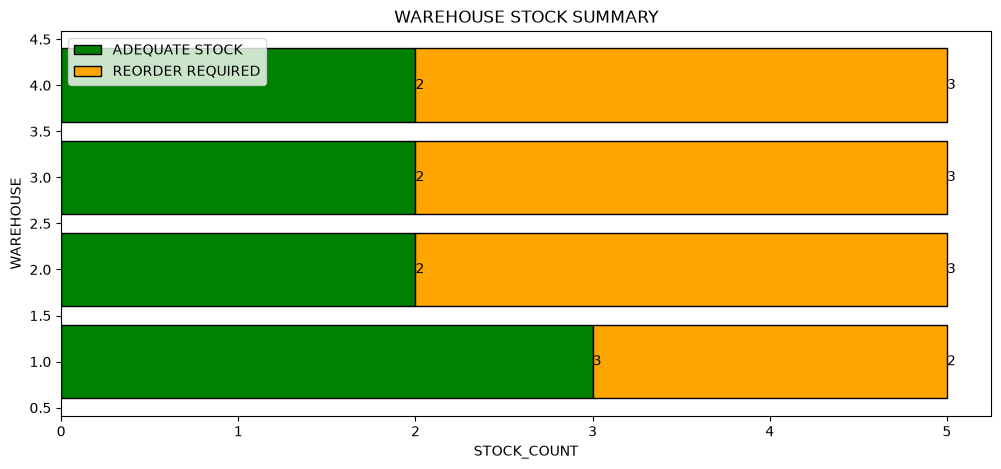

In [198]:
# VISUAL 5  - warehouse stock analysis

import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize = (12,5))
bar1 = ax.barh(warehouse_stock_summary.index,
        warehouse_stock_summary["ADEQUATE STOCK"],
        label = "ADEQUATE STOCK",color = "green",edgecolor = "black"
              )
bar2 = ax.barh(warehouse_stock_summary.index,
        warehouse_stock_summary["REORDER REQUIRED"],
        left = warehouse_stock_summary["ADEQUATE STOCK"],
        label = "REORDER REQUIRED",color = "orange",edgecolor = "black"
       )
ax.bar_label(bar1)
ax.bar_label(bar2)
ax.set_xlabel("STOCK_COUNT")
ax.set_ylabel("WAREHOUSE")
ax.set_title("WAREHOUSE STOCK SUMMARY")
ax.legend()
plt.show()

In [205]:
# MONTHLY ON_TIME DELIVERY TREND

monthly_delivery = valid_completed_orders.copy()
monthly_delivery["order_month"] = monthly_delivery["order_date"].dt.to_period("M")
monthly_performance = monthly_delivery.groupby("order_month",as_index = False).agg(
    total_completed_orders = ("order_id","count"),
    on_time_orders = ("is_on_time","sum")
)
monthly_performance["on_time_delivery_rate"] = round((monthly_performance["on_time_orders"]/monthly_performance["total_completed_orders"]) * 100,2)
monthly_performance

,order_month,total_completed_orders,on_time_orders,on_time_delivery_rate
0,2025-01,10,6,60.00
1,2025-02,8,5,62.50
2,2025-03,9,5,55.56


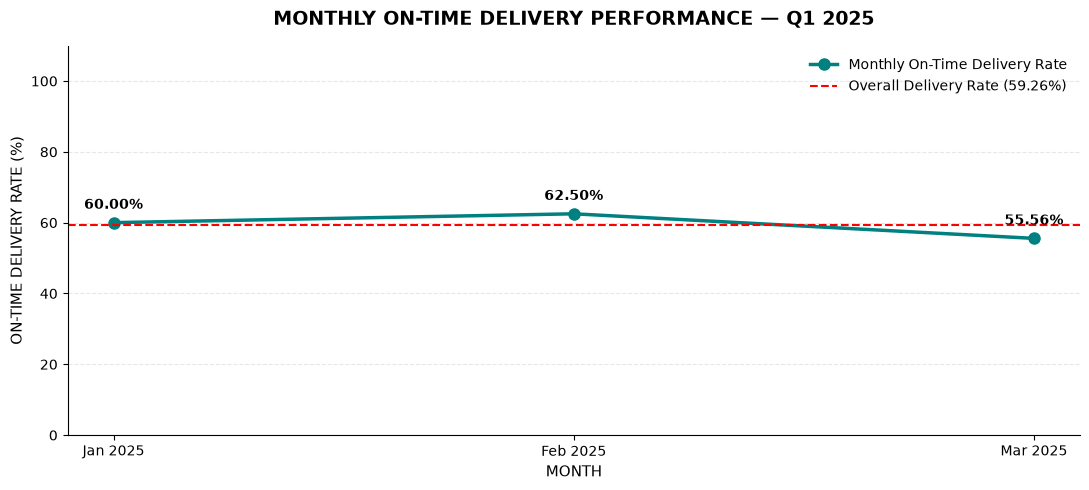

In [213]:
# VISUAL 6 - MONTHLY ON_TIME DELIVERY PERFORMANCE

# Prepare monthly labels
months = monthly_performance["order_month"].dt.strftime("%b %Y")

# Calculate overall on-time delivery rate
overall_rate = (
    monthly_performance["on_time_orders"].sum() /
    monthly_performance["total_completed_orders"].sum()
) * 100

# Create figure
fig, ax = plt.subplots(figsize=(11, 5))

# Plot monthly on-time delivery rate
ax.plot(
    months,
    monthly_performance["on_time_delivery_rate"],
    marker="o",
    markersize=8,
    linewidth=2.5,
    color="teal",
    label="Monthly On-Time Delivery Rate"
)

# Overall performance reference line
ax.axhline(
    y=overall_rate,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall Delivery Rate ({overall_rate:.2f}%)"
)

# Add percentage labels to each point
for month, rate in zip(
    months,
    monthly_performance["on_time_delivery_rate"]
):
    ax.annotate(
        f"{rate:.2f}%",
        xy=(month, rate),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

# Chart formatting
ax.set_title(
    "MONTHLY ON-TIME DELIVERY PERFORMANCE — Q1 2025",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("MONTH", fontsize = 11)
ax.set_ylabel("ON-TIME DELIVERY RATE (%)", fontsize=11)

ax.set_ylim(0, 110)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Add legend
ax.legend(loc="best", frameon=False)

# Adjust spacing
fig.tight_layout()

plt.show()

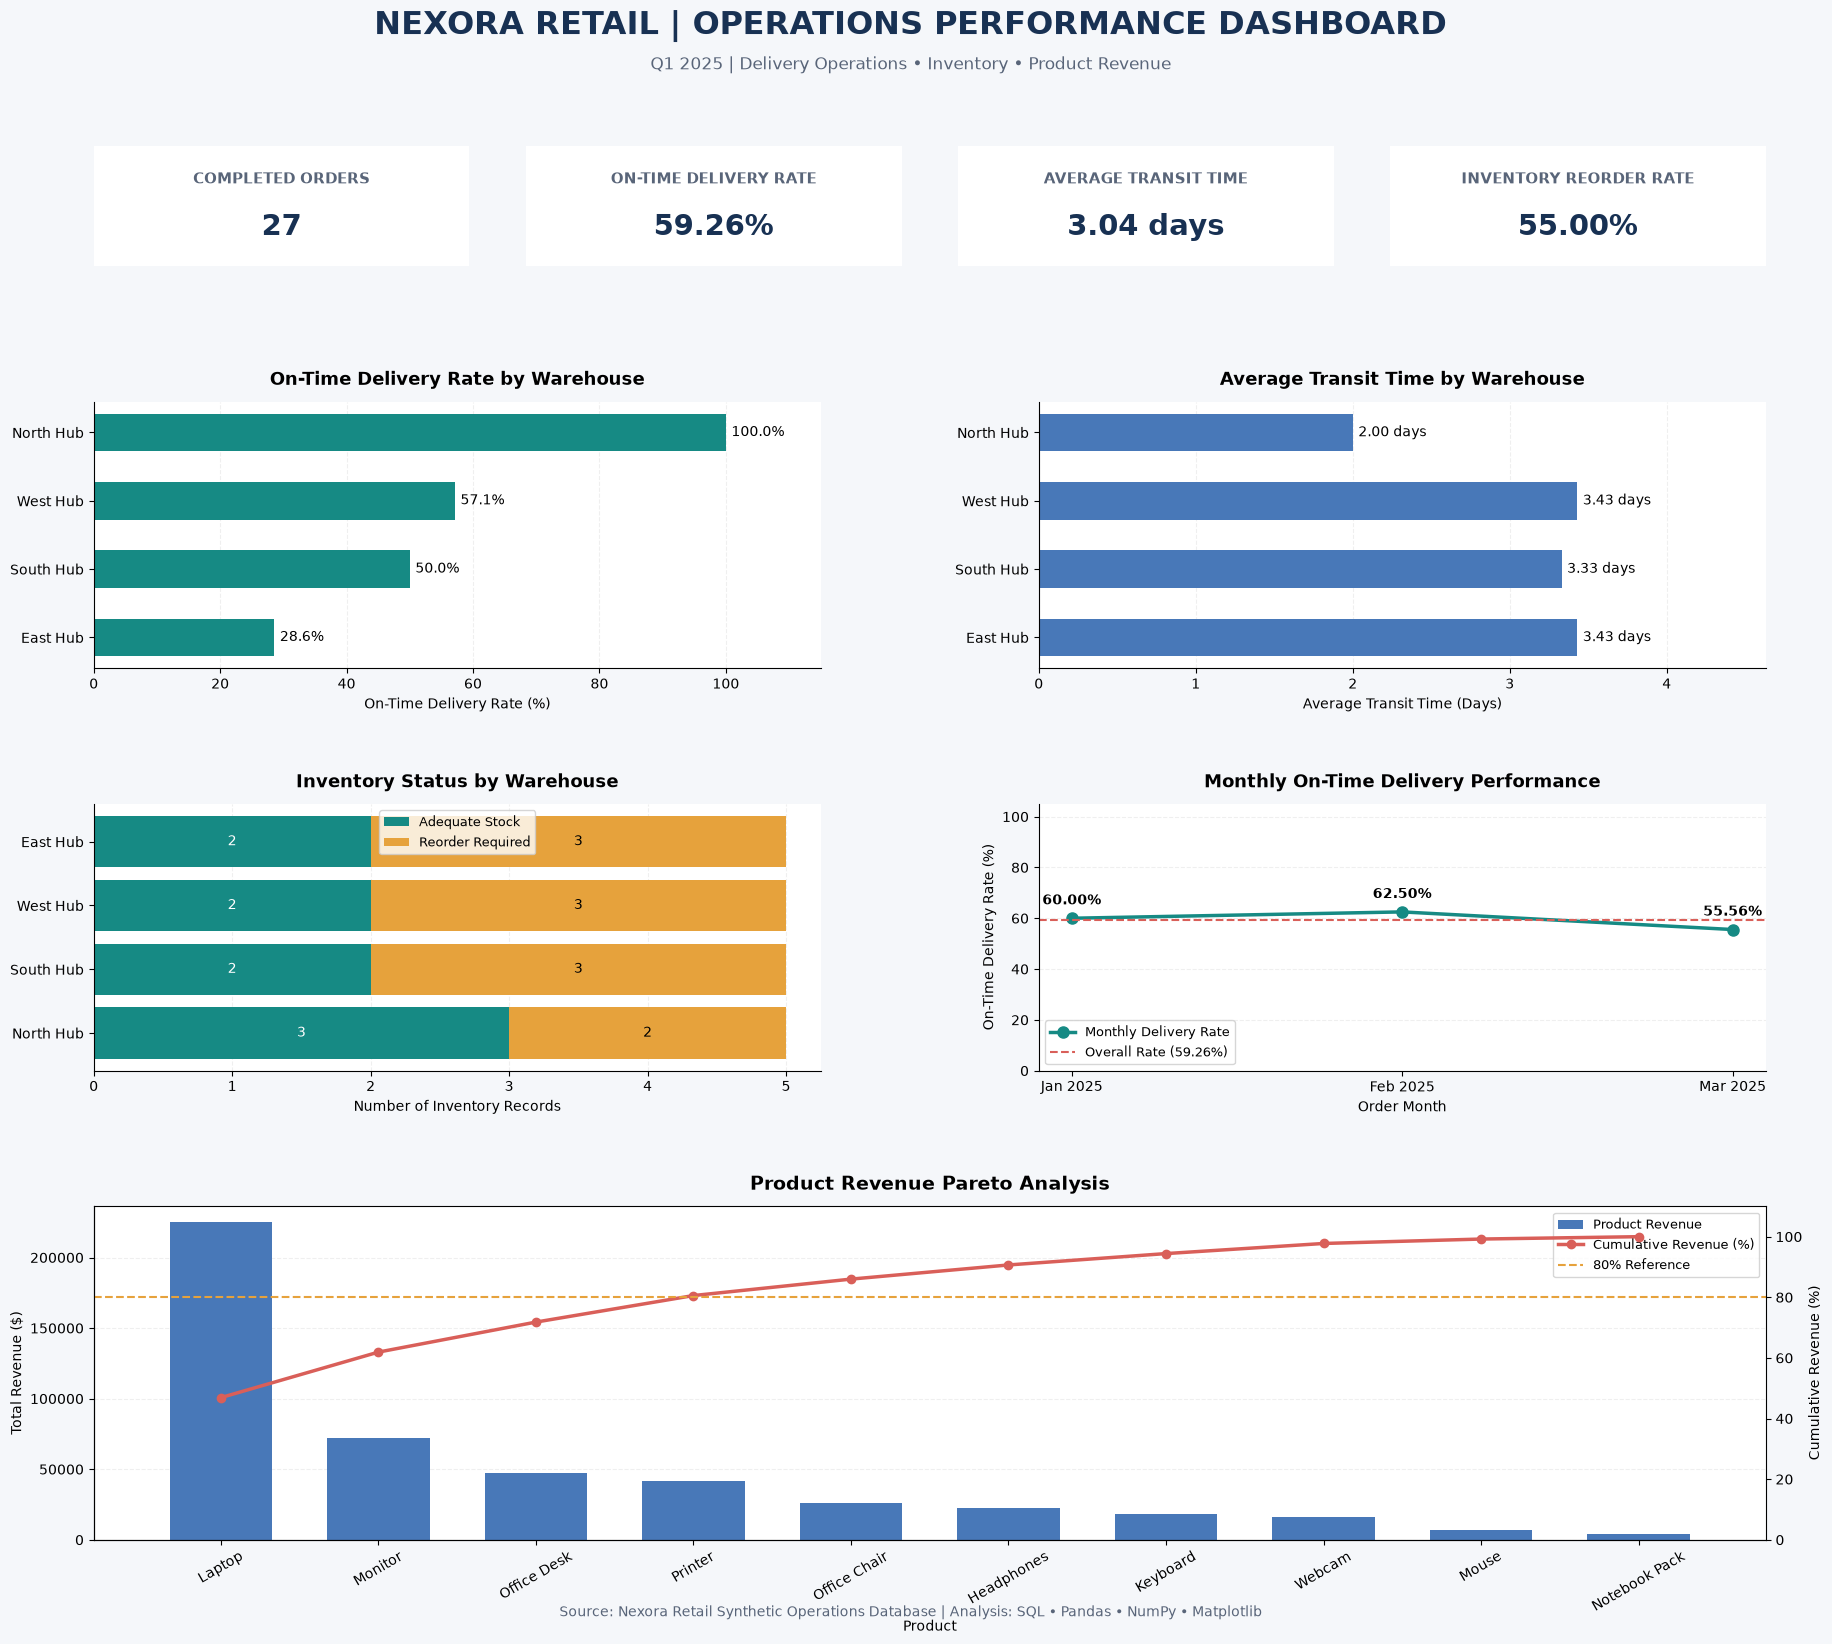

In [214]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. PREPARE DATA FOR DASHBOARD
# ============================================================

# Warehouse performance
warehouse_dashboard = warehouse_performance_2.merge(
    warehouses_df[["warehouse_id", "warehouse_name"]],
    on="warehouse_id",
    how="left"
)

warehouse_dashboard = warehouse_dashboard.sort_values(
    "on_time_delivery_rate",
    ascending=True
)

# Inventory performance
inventory_dashboard = warehouse_stock_summary.copy()

inventory_dashboard = inventory_dashboard[
    ["ADEQUATE STOCK", "REORDER REQUIRED"]
]

inventory_dashboard = inventory_dashboard.merge(
    warehouses_df[["warehouse_id", "warehouse_name"]],
    left_index=True,
    right_on="warehouse_id",
    how="left"
).set_index("warehouse_name")

# Monthly delivery performance
monthly_dashboard = monthly_performance.sort_values(
    "order_month"
).copy()

monthly_dashboard["month_label"] = (
    monthly_dashboard["order_month"].dt.strftime("%b %Y")
)

# Product revenue performance
pareto_dashboard = product_performance.sort_values(
    "total_revenue",
    ascending=False
).copy()

pareto_dashboard["revenue_contribution"] = (
    pareto_dashboard["total_revenue"] /
    pareto_dashboard["total_revenue"].sum()
) * 100

pareto_dashboard["cumulative_revenue_pct"] = (
    pareto_dashboard["revenue_contribution"].cumsum()
)


# ============================================================
# 2. CALCULATE DASHBOARD KPIs
# ============================================================

total_completed_orders = len(valid_completed_orders)

overall_on_time_rate = (
    valid_completed_orders["is_on_time"].mean() * 100
)

average_transit_time = (
    valid_completed_orders["delivery_days"].mean()
)

inventory_reorder_rate = (
    (inventory_analysis["stock_status"] == "REORDER REQUIRED").mean()
    * 100
)


# ============================================================
# 3. CREATE FIGURE AND GRIDSPEC LAYOUT
# ============================================================

fig = plt.figure(figsize=(19, 17), facecolor="#F5F7FA")

gs = fig.add_gridspec(
    nrows=4,
    ncols=2,
    height_ratios=[0.45, 1, 1, 1.25],
    hspace=0.55,
    wspace=0.30,
    left=0.07,
    right=0.95,
    top=0.89,
    bottom=0.07
)

# KPI card axes
kpi_grid = gs[0, :].subgridspec(1, 4, wspace=0.15)

kpi_axes = [
    fig.add_subplot(kpi_grid[0, i])
    for i in range(4)
]

# Chart axes
ax1 = fig.add_subplot(gs[1, 0])
ax2 = fig.add_subplot(gs[1, 1])

ax3 = fig.add_subplot(gs[2, 0])
ax4 = fig.add_subplot(gs[2, 1])

ax5 = fig.add_subplot(gs[3, :])


# ============================================================
# 4. DASHBOARD TITLE
# ============================================================

fig.suptitle(
    "NEXORA RETAIL | OPERATIONS PERFORMANCE DASHBOARD",
    fontsize=23,
    fontweight="bold",
    color="#183153",
    y=0.97
)

fig.text(
    0.5,
    0.935,
    "Q1 2025 | Delivery Operations • Inventory • Product Revenue",
    ha="center",
    fontsize=12,
    color="#596579"
)


# ============================================================
# 5. KPI CARDS
# ============================================================

kpi_values = [
    f"{total_completed_orders:,}",
    f"{overall_on_time_rate:.2f}%",
    f"{average_transit_time:.2f} days",
    f"{inventory_reorder_rate:.2f}%"
]

kpi_titles = [
    "COMPLETED ORDERS",
    "ON-TIME DELIVERY RATE",
    "AVERAGE TRANSIT TIME",
    "INVENTORY REORDER RATE"
]

for ax, title, value in zip(kpi_axes, kpi_titles, kpi_values):

    ax.set_facecolor("white")

    ax.text(
        0.5, 0.72,
        title,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#596579",
        transform=ax.transAxes
    )

    ax.text(
        0.5, 0.32,
        value,
        ha="center",
        va="center",
        fontsize=21,
        fontweight="bold",
        color="#183153",
        transform=ax.transAxes
    )

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)


# ============================================================
# 6. CHART 1 — WAREHOUSE ON-TIME DELIVERY RATE
# ============================================================

bars1 = ax1.barh(
    warehouse_dashboard["warehouse_name"],
    warehouse_dashboard["on_time_delivery_rate"],
    color="#168A84",
    height=0.55
)

ax1.bar_label(
    bars1,
    fmt="%.1f%%",
    padding=4,
    fontsize=10
)

ax1.set_title(
    "On-Time Delivery Rate by Warehouse",
    fontsize=13,
    fontweight="bold",
    pad=12
)

ax1.set_xlabel("On-Time Delivery Rate (%)")
ax1.set_xlim(0, 115)


# ============================================================
# 7. CHART 2 — AVERAGE TRANSIT TIME
# ============================================================

bars2 = ax2.barh(
    warehouse_dashboard["warehouse_name"],
    warehouse_dashboard["avg_transit_time"],
    color="#4878B8",
    height=0.55
)

ax2.bar_label(
    bars2,
    fmt="%.2f days",
    padding=4,
    fontsize=10
)

ax2.set_title(
    "Average Transit Time by Warehouse",
    fontsize=13,
    fontweight="bold",
    pad=12
)

ax2.set_xlabel("Average Transit Time (Days)")
ax2.set_xlim(0, warehouse_dashboard["avg_transit_time"].max() * 1.35)


# ============================================================
# 8. CHART 3 — INVENTORY STATUS BY WAREHOUSE
# ============================================================

bars3a = ax3.barh(
    inventory_dashboard.index,
    inventory_dashboard["ADEQUATE STOCK"],
    color="#168A84",
    label="Adequate Stock"
)

bars3b = ax3.barh(
    inventory_dashboard.index,
    inventory_dashboard["REORDER REQUIRED"],
    left=inventory_dashboard["ADEQUATE STOCK"],
    color="#E6A23C",
    label="Reorder Required"
)

ax3.bar_label(
    bars3a,
    label_type="center",
    fontsize=10,
    color="white"
)

ax3.bar_label(
    bars3b,
    label_type="center",
    fontsize=10,
    color="black"
)

ax3.set_title(
    "Inventory Status by Warehouse",
    fontsize=13,
    fontweight="bold",
    pad=12
)

ax3.set_xlabel("Number of Inventory Records")
ax3.legend(loc="upper center", fontsize=9)


# ============================================================
# 9. CHART 4 — MONTHLY ON-TIME DELIVERY TREND
# ============================================================

months = monthly_dashboard["month_label"]

monthly_rates = monthly_dashboard["on_time_delivery_rate"]

ax4.plot(
    months,
    monthly_rates,
    color="#168A84",
    marker="o",
    markersize=8,
    linewidth=2.5,
    label="Monthly Delivery Rate"
)

ax4.axhline(
    overall_on_time_rate,
    color="#D95F59",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall Rate ({overall_on_time_rate:.2f}%)"
)

for month, rate in zip(months, monthly_rates):

    offset = -16 if rate >= 90 else 10

    ax4.annotate(
        f"{rate:.2f}%",
        xy=(month, rate),
        xytext=(0, offset),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax4.set_title(
    "Monthly On-Time Delivery Performance",
    fontsize=13,
    fontweight="bold",
    pad=12
)

ax4.set_xlabel("Order Month")
ax4.set_ylabel("On-Time Delivery Rate (%)")
ax4.set_ylim(0, 105)

ax4.legend(loc="lower left", fontsize=9)


# ============================================================
# 10. CHART 5 — PRODUCT REVENUE PARETO ANALYSIS
# ============================================================

bars5 = ax5.bar(
    pareto_dashboard["product_name"],
    pareto_dashboard["total_revenue"],
    color="#4878B8",
    width=0.65,
    label="Product Revenue"
)

ax5.set_title(
    "Product Revenue Pareto Analysis",
    fontsize=14,
    fontweight="bold",
    pad=12
)

ax5.set_ylabel("Total Revenue ($)")
ax5.set_xlabel("Product")

ax5.tick_params(axis="x", rotation=30)

# Secondary y-axis for cumulative percentage
ax5_secondary = ax5.twinx()

ax5_secondary.plot(
    pareto_dashboard["product_name"],
    pareto_dashboard["cumulative_revenue_pct"],
    color="#D95F59",
    marker="o",
    linewidth=2.5,
    label="Cumulative Revenue (%)"
)

ax5_secondary.axhline(
    y=80,
    color="#E6A23C",
    linestyle="--",
    linewidth=1.5,
    label="80% Reference"
)

ax5_secondary.set_ylabel("Cumulative Revenue (%)")
ax5_secondary.set_ylim(0, 110)

# Combined legend
handles1, labels1 = ax5.get_legend_handles_labels()

handles2, labels2 = ax5_secondary.get_legend_handles_labels()

ax5.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="upper right",
    fontsize=9
)


# ============================================================
# 11. APPLY CONSISTENT FORMATTING
# ============================================================

for ax in [ax1, ax2, ax3, ax4, ax5]:

    ax.set_facecolor("white")

    ax.grid(
        axis="x" if ax in [ax1, ax2, ax3] else "y",
        linestyle="--",
        alpha=0.2
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


# ============================================================
# 12. ADD FOOTER
# ============================================================

fig.text(
    0.5,
    0.025,
    "Source: Nexora Retail Synthetic Operations Database | "
    "Analysis: SQL • Pandas • NumPy • Matplotlib",
    ha="center",
    fontsize=10,
    color="#596579"
)


# ============================================================
# 13. SAVE AND DISPLAY DASHBOARD
# ============================================================

fig.savefig(
    "nexora_operations_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()